# Distance Experiment
This experiment involves seeing how much choosing locations closer to a user affects a user's rankings compared to the original BPR. 

In [16]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.distance import add_distance_scores

pd.set_option("display.max_columns", None)

In [17]:
bpr_candidates = pd.read_parquet(
    ROOT / "data" / "processed" / "bpr_candidates.parquet"
)

print("Users:", bpr_candidates["user_id"].nunique())
print("Candidate rows:", len(bpr_candidates))

display(bpr_candidates.head())

Users: 50
Candidate rows: 10000


,gmap_id,bpr_score,bpr_rank,name,category,activity_groups,bpr_normalized,user_id,price
0,0x89c258e461d380bb:0xe68debf701c7301e,2.615392,1,P.J. Clarke's,"[American restaurant, Bar, Hamburger restauran...",[Food & Drink],1.000000,111679270882673893030,$$
1,0x89c259f568ae3a11:0x4de0e0aa48068655,2.559453,2,Bubby's,"[American restaurant, Bakery, Bar, Breakfast r...",[Food & Drink],0.864778,111679270882673893030,$$
2,0x89c25901805ed947:0x9c3d57c181395b6b,2.550491,3,Oyster,"[Bar, American restaurant, Oyster bar restaura...",[Food & Drink],0.843114,111679270882673893030,$$
3,0x89c259a66c2e3131:0xb070d578897c3982,2.548381,4,ILILI,"[Lebanese restaurant, Bar, Brunch restaurant, ...",[Food & Drink],0.838012,111679270882673893030,$$$
4,0x89c2598c6bbbbe33:0x72df042a34bc2a5f,2.531472,5,Ladurée,"[Cake shop, Chocolate shop, Gourmet grocery st...",[Food & Drink],0.797139,111679270882673893030,$$$


In [18]:
activity_df = pd.read_csv(
    ROOT / "data" / "processed" / "activity_dataset.csv"
)

print(activity_df.columns.tolist())

['name', 'address', 'gmap_id', 'description', 'latitude', 'longitude', 'category', 'avg_rating', 'num_of_reviews', 'price', 'hours', 'MISC', 'state', 'relative_results', 'url', 'is_activity', 'activity_groups']


In [19]:
coordinates = (
    activity_df[
        ["gmap_id", "latitude", "longitude"]
    ]
    .drop_duplicates("gmap_id")
)

bpr_candidates = bpr_candidates.merge(
    coordinates,
    on="gmap_id",
    how="left",
    validate="many_to_one"
)

display(
    bpr_candidates[
        ["user_id", "gmap_id", "latitude", "longitude"]
    ].head()
)

,user_id,gmap_id,latitude,longitude
0,111679270882673893030,0x89c258e461d380bb:0xe68debf701c7301e,40.758973,-73.968193
1,111679270882673893030,0x89c259f568ae3a11:0x4de0e0aa48068655,40.719819,-74.008383
2,111679270882673893030,0x89c25901805ed947:0x9c3d57c181395b6b,40.752482,-73.977431
3,111679270882673893030,0x89c259a66c2e3131:0xb070d578897c3982,40.744358,-73.987736
4,111679270882673893030,0x89c2598c6bbbbe33:0x72df042a34bc2a5f,40.724296,-74.002452


In [20]:
metadata = pd.read_json(
    ROOT / "data" / "raw" / "meta-New_York.json.gz",
    lines=True,
    compression="gzip"
)

print(metadata.columns.tolist())

['name', 'address', 'gmap_id', 'description', 'latitude', 'longitude', 'category', 'avg_rating', 'num_of_reviews', 'price', 'hours', 'MISC', 'state', 'relative_results', 'url']


## validate coordinates

In [21]:
for col in ["latitude", "longitude"]:
    bpr_candidates[col] = pd.to_numeric(
        bpr_candidates[col],
        errors="coerce"
    )

valid_coordinates = (
    bpr_candidates["latitude"].between(-90, 90)
    & bpr_candidates["longitude"].between(-180, 180)
)

bpr_candidates.loc[
    ~valid_coordinates,
    ["latitude", "longitude"]
] = np.nan

print("Missing/invalid coordinates:",
      (~valid_coordinates).sum())

print("Coordinate coverage:",
      f"{valid_coordinates.mean():.2%}")

Missing/invalid coordinates: 0
Coordinate coverage: 100.00%


## Distance Compatibility

Distance is calculated using geodesic distance between
the user's location and the activity's coordinates.

D(u,a) = max(-1, 1 - distance(u,a) / radius)

In [51]:
# Simulated location: Times Square, Manhattan
USER_LOCATION = (40.7580, -73.9855)

RADII = [2, 5, 10]

DISTANCE_WEIGHTS = [
    0.0,
    0.05,
    0.1,
    0.15,
    0.2, 
    0.25,
    0.3, 
    0.35,
    0.4
]

K = 10

evaluation_users = bpr_candidates["user_id"].unique()

## test one user

In [52]:
user_id = evaluation_users[0]

user_candidates = bpr_candidates[
    bpr_candidates["user_id"] == user_id
].copy()

scored = add_distance_scores(
    candidates=user_candidates,
    user_location=USER_LOCATION,
    radius_miles=5
)

scored["final_score"] = (
    scored["bpr_normalized"]
    + 0.1 * scored["distance_score"]
)

ranked = scored.sort_values(
    ["final_score", "bpr_rank"],
    ascending=[False, True]
)

display(
    ranked[
        [
            "name",
            "distance_miles",
            "distance_score",
            "bpr_rank",
            "final_score"
        ]
    ].head(10)
)

,name,distance_miles,distance_score,bpr_rank,final_score
0,P.J. Clarke's,0.910593,0.817881,1,1.081788
2,Oyster,0.569404,0.886119,3,0.931726
3,ILILI,0.948600,0.810280,4,0.919040
1,Bubby's,2.895422,0.420916,2,0.906870
5,Toloache,0.291411,0.941718,6,0.861183
4,Ladurée,2.490023,0.501995,5,0.847339
6,Nobu Fifty Seven,0.625104,0.874979,7,0.794914
7,Refinery Rooftop,0.396108,0.920778,8,0.792246
9,The Modern,0.508659,0.898268,10,0.738265
8,Nom Wah Tea Parlor,3.079076,0.384185,9,0.709212


In [53]:
def distance_metrics(top_k, radius):
    known = top_k.dropna(subset=["distance_miles"])

    if len(known) == 0:
        return {
            "avg_distance": np.nan,
            "within_radius_rate": np.nan,
            "missing_coordinate_rate": 1.0
        }

    return {
        "avg_distance": known["distance_miles"].mean(),
        "within_radius_rate": (
            known["distance_miles"] <= radius
        ).mean(),
        "missing_coordinate_rate": (
            top_k["distance_miles"].isna().mean()
        )
    }

## multiuser experiment

In [54]:
all_results = []
all_top10 = []

for user_id, user_candidates in bpr_candidates.groupby("user_id"):

    if len(user_candidates) < K:
        continue

    baseline_ids = set(
        user_candidates.sort_values("bpr_rank")
        .head(K)["gmap_id"]
    )

    for radius in RADII:

        # Calculate distance once per user and radius
        scored = add_distance_scores(
            candidates=user_candidates,
            user_location=USER_LOCATION,
            radius_miles=radius
        )

        for weight in DISTANCE_WEIGHTS:

            ranked = scored.copy()

            ranked["final_score"] = (
                ranked["bpr_normalized"]
                + weight * ranked["distance_score"]
            )

            ranked = ranked.sort_values(
                ["final_score", "bpr_rank"],
                ascending=[False, True]
            )

            top10 = ranked.head(K).copy()

            metrics = distance_metrics(top10, radius)

            overlap = (
                len(set(top10["gmap_id"]) & baseline_ids)
                / K
            )

            all_results.append({
                "user_id": user_id,
                "radius_miles": radius,
                "distance_weight": weight,
                "avg_distance": metrics["avg_distance"],
                "within_radius_rate": metrics["within_radius_rate"],
                "missing_coordinate_rate":
                    metrics["missing_coordinate_rate"],
                "bpr_top10_overlap": overlap
            })

            top10["radius_miles"] = radius
            top10["distance_weight"] = weight
            top10["final_rank"] = np.arange(1, len(top10) + 1)

            all_top10.append(top10)

distance_results = pd.DataFrame(all_results)
distance_top10 = pd.concat(all_top10, ignore_index=True)

display(distance_results.head())

,user_id,radius_miles,distance_weight,avg_distance,within_radius_rate,missing_coordinate_rate,bpr_top10_overlap
0,100388958952721979686,2,0.00,9.121842,0.0,0.0,1.0
1,100388958952721979686,2,0.05,9.121842,0.0,0.0,1.0
2,100388958952721979686,2,0.10,9.121842,0.0,0.0,1.0
3,100388958952721979686,2,0.15,9.121842,0.0,0.0,1.0
4,100388958952721979686,2,0.20,9.121842,0.0,0.0,1.0


In [55]:
distance_summary = (
    distance_results
    .groupby(["radius_miles", "distance_weight"])
    .agg(
        avg_distance=("avg_distance", "mean"),
        within_radius_rate=("within_radius_rate", "mean"),
        missing_coordinate_rate=(
            "missing_coordinate_rate", "mean"
        ),
        bpr_top10_overlap=("bpr_top10_overlap", "mean")
    )
    .reset_index()
)

display(distance_summary)

,radius_miles,distance_weight,avg_distance,within_radius_rate,missing_coordinate_rate,bpr_top10_overlap
0,2,0.00,42.721421,0.144,0.0,1.000
1,2,0.05,42.107132,0.168,0.0,0.972
2,2,0.10,41.768067,0.188,0.0,0.948
3,2,0.15,40.542317,0.212,0.0,0.918
4,2,0.20,39.721276,0.242,0.0,0.886
5,2,0.25,39.336488,0.256,0.0,0.872
6,2,0.30,38.397206,0.282,0.0,0.840
7,2,0.35,37.885273,0.296,0.0,0.828
8,2,0.40,37.731105,0.318,0.0,0.806
9,5,0.00,42.721421,0.320,0.0,1.000


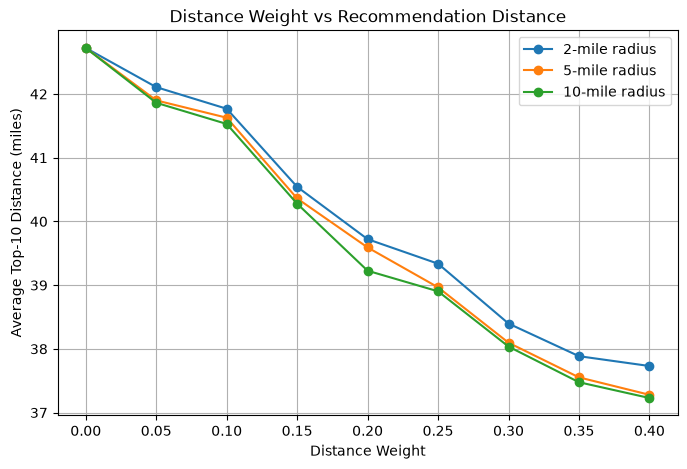

In [56]:
plt.figure(figsize=(8, 5))

for radius in RADII:
    subset = distance_summary[
        distance_summary["radius_miles"] == radius
    ]

    plt.plot(
        subset["distance_weight"],
        subset["avg_distance"],
        marker="o",
        label=f"{radius}-mile radius"
    )

plt.xlabel("Distance Weight")
plt.ylabel("Average Top-10 Distance (miles)")
plt.title("Distance Weight vs Recommendation Distance")
plt.legend()
plt.grid(True)
plt.show()

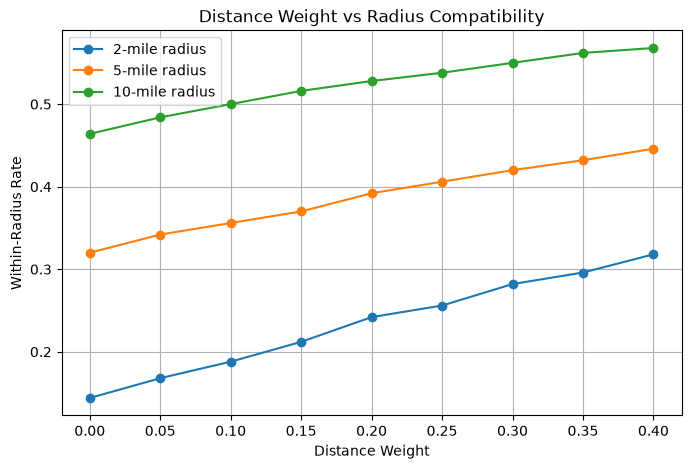

In [57]:
plt.figure(figsize=(8, 5))

for radius in RADII:
    subset = distance_summary[
        distance_summary["radius_miles"] == radius
    ]

    plt.plot(
        subset["distance_weight"],
        subset["within_radius_rate"],
        marker="o",
        label=f"{radius}-mile radius"
    )

plt.xlabel("Distance Weight")
plt.ylabel("Within-Radius Rate")
plt.title("Distance Weight vs Radius Compatibility")
plt.legend()
plt.grid(True)
plt.show()

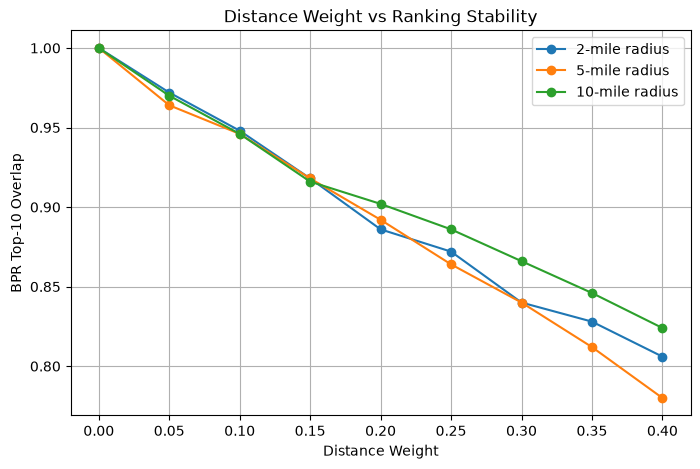

In [58]:
plt.figure(figsize=(8, 5))

for radius in RADII:
    subset = distance_summary[
        distance_summary["radius_miles"] == radius
    ]

    plt.plot(
        subset["distance_weight"],
        subset["bpr_top10_overlap"],
        marker="o",
        label=f"{radius}-mile radius"
    )

plt.xlabel("Distance Weight")
plt.ylabel("BPR Top-10 Overlap")
plt.title("Distance Weight vs Ranking Stability")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
baseline = (
    distance_summary[
        distance_summary["distance_weight"] == 0
    ][["radius_miles", "avg_distance", "within_radius_rate"]]
    .rename(columns={
        "avg_distance": "baseline_distance",
        "within_radius_rate": "baseline_within_radius"
    })
)

comparison = distance_summary.merge(
    baseline,
    on="radius_miles"
)

comparison["distance_reduction"] = (
    comparison["baseline_distance"]
    - comparison["avg_distance"]
)

comparison["within_radius_improvement"] = (
    comparison["within_radius_rate"]
    - comparison["baseline_within_radius"]
)

display(comparison)

,radius_miles,distance_weight,avg_distance,within_radius_rate,missing_coordinate_rate,bpr_top10_overlap,baseline_distance,baseline_within_radius,distance_reduction,within_radius_improvement
0,2,0.00,42.721421,0.144,0.0,1.000,42.721421,0.144,0.000000,0.000
1,2,0.05,42.107132,0.168,0.0,0.972,42.721421,0.144,0.614290,0.024
2,2,0.10,41.768067,0.188,0.0,0.948,42.721421,0.144,0.953354,0.044
3,2,0.15,40.542317,0.212,0.0,0.918,42.721421,0.144,2.179104,0.068
4,2,0.20,39.721276,0.242,0.0,0.886,42.721421,0.144,3.000145,0.098
5,5,0.00,42.721421,0.320,0.0,1.000,42.721421,0.320,0.000000,0.000
6,5,0.05,41.899323,0.342,0.0,0.964,42.721421,0.320,0.822098,0.022
7,5,0.10,41.627470,0.356,0.0,0.946,42.721421,0.320,1.093951,0.036
8,5,0.15,40.360034,0.370,0.0,0.918,42.721421,0.320,2.361387,0.050
9,5,0.20,39.591290,0.392,0.0,0.892,42.721421,0.320,3.130131,0.072


## Hybrid (soft-ranking + radius aware)

In [31]:
def hybrid_distance_rerank(
    candidates,
    user_location,
    radius_miles,
    distance_weight=0.1,
    k=10
):
    scored = add_distance_scores(
        candidates=candidates,
        user_location=user_location,
        radius_miles=radius_miles
    ).copy()

    scored["final_score"] = (
        scored["bpr_normalized"]
        + distance_weight * scored["distance_score"]
    )

    # Eligible activities: known distance and within radius
    inside = scored[
        scored["distance_miles"].notna()
        & (scored["distance_miles"] <= radius_miles)
    ].copy()

    # Remaining activities
    outside = scored[
        scored["distance_miles"].isna()
        | (scored["distance_miles"] > radius_miles)
    ].copy()

    # Rank eligible activities first
    inside = inside.sort_values(
        ["final_score", "bpr_rank"],
        ascending=[False, True]
    )

    outside = outside.sort_values(
        ["final_score", "bpr_rank"],
        ascending=[False, True]
    )

    inside["selection_type"] = "within_radius"
    outside["selection_type"] = "fallback"

    # Fill Top-K with eligible activities first
    top_k = pd.concat(
        [inside, outside],
        ignore_index=True
    ).head(k).copy()

    top_k["final_rank"] = np.arange(
        1, len(top_k) + 1
    )

    return top_k

In [32]:

user_id = evaluation_users[0]

user_candidates = bpr_candidates[
    bpr_candidates["user_id"] == user_id
].copy()

hybrid_top10 = hybrid_distance_rerank(
    candidates=user_candidates,
    user_location=USER_LOCATION,
    radius_miles=5,
    distance_weight=0.1,
    k=K
)

display(
    hybrid_top10[
        [
            "name",
            "bpr_rank",
            "bpr_normalized",
            "distance_miles",
            "distance_score",
            "final_score",
            "selection_type",
            "final_rank"
        ]
    ]
)

print(
    "Within-radius activities:",
    (hybrid_top10["selection_type"] == "within_radius").sum()
)

print(
    "Fallback activities:",
    (hybrid_top10["selection_type"] == "fallback").sum()
)


,name,bpr_rank,bpr_normalized,distance_miles,distance_score,final_score,selection_type,final_rank
0,P.J. Clarke's,1,1.000000,0.910593,0.817881,1.081788,within_radius,1
1,Oyster,3,0.843114,0.569404,0.886119,0.931726,within_radius,2
2,ILILI,4,0.838012,0.948600,0.810280,0.919040,within_radius,3
3,Bubby's,2,0.864778,2.895422,0.420916,0.906870,within_radius,4
4,Toloache,6,0.767011,0.291411,0.941718,0.861183,within_radius,5
5,Ladurée,5,0.797139,2.490023,0.501995,0.847339,within_radius,6
6,Nobu Fifty Seven,7,0.707416,0.625104,0.874979,0.794914,within_radius,7
7,Refinery Rooftop,8,0.700169,0.396108,0.920778,0.792246,within_radius,8
8,The Modern,10,0.648438,0.508659,0.898268,0.738265,within_radius,9
9,Nom Wah Tea Parlor,9,0.670794,3.079076,0.384185,0.709212,within_radius,10


Within-radius activities: 10
Fallback activities: 0


In [33]:
COMPARISON_WEIGHT = 0.1

strategy_results = []

for user_id, user_candidates in bpr_candidates.groupby("user_id"):

    if len(user_candidates) < K:
        continue

    baseline_top10 = (
        user_candidates
        .sort_values("bpr_rank")
        .head(K)
    )

    baseline_ids = set(baseline_top10["gmap_id"])

    for radius in RADII:

        scored = add_distance_scores(
            candidates=user_candidates,
            user_location=USER_LOCATION,
            radius_miles=radius
        )

        # Strategy 1: Original BPR
        bpr_top10 = (
            scored.sort_values("bpr_rank")
            .head(K)
        )

        # Strategy 2: Soft reranking
        soft = scored.copy()

        soft["final_score"] = (
            soft["bpr_normalized"]
            + COMPARISON_WEIGHT * soft["distance_score"]
        )

        soft_top10 = (
            soft.sort_values(
                ["final_score", "bpr_rank"],
                ascending=[False, True]
            )
            .head(K)
        )

        # Strategy 3: Hybrid reranking
        hybrid_top10 = hybrid_distance_rerank(
            candidates=user_candidates,
            user_location=USER_LOCATION,
            radius_miles=radius,
            distance_weight=COMPARISON_WEIGHT,
            k=K
        )

        strategies = {
            "BPR": bpr_top10,
            "Soft": soft_top10,
            "Hybrid": hybrid_top10
        }

        for strategy, top10 in strategies.items():

            metrics = distance_metrics(top10, radius)

            overlap = (
                len(set(top10["gmap_id"]) & baseline_ids)
                / K
            )

            within_count = (
                top10["distance_miles"].le(radius).sum()
            )

            strategy_results.append({
                "user_id": user_id,
                "radius_miles": radius,
                "strategy": strategy,
                "avg_distance": metrics["avg_distance"],
                "within_radius_rate":
                    metrics["within_radius_rate"],
                "missing_coordinate_rate":
                    metrics["missing_coordinate_rate"],
                "bpr_top10_overlap": overlap,
                "within_radius_count": within_count,
                "recommendation_count": len(top10)
            })

strategy_results = pd.DataFrame(strategy_results)

display(strategy_results.head())


,user_id,radius_miles,strategy,avg_distance,within_radius_rate,missing_coordinate_rate,bpr_top10_overlap,within_radius_count,recommendation_count
0,100388958952721979686,2,BPR,9.121842,0.0,0.0,1.0,0,10
1,100388958952721979686,2,Soft,9.121842,0.0,0.0,1.0,0,10
2,100388958952721979686,2,Hybrid,9.121842,0.0,0.0,1.0,0,10
3,100388958952721979686,5,BPR,9.121842,0.0,0.0,1.0,0,10
4,100388958952721979686,5,Soft,8.768352,0.0,0.0,0.9,0,10


In [34]:

strategy_summary = (
    strategy_results
    .groupby(["radius_miles", "strategy"])
    .agg(
        avg_distance=("avg_distance", "mean"),
        within_radius_rate=("within_radius_rate", "mean"),
        missing_coordinate_rate=(
            "missing_coordinate_rate", "mean"
        ),
        bpr_top10_overlap=("bpr_top10_overlap", "mean"),
        avg_within_radius_count=(
            "within_radius_count", "mean"
        ),
        avg_recommendation_count=(
            "recommendation_count", "mean"
        )
    )
    .reset_index()
)

display(strategy_summary.round(3))


,radius_miles,strategy,avg_distance,within_radius_rate,missing_coordinate_rate,bpr_top10_overlap,avg_within_radius_count,avg_recommendation_count
0,2,BPR,42.721,0.144,0.0,1.000,1.44,10.0
1,2,Hybrid,36.976,0.408,0.0,0.736,4.08,10.0
2,2,Soft,41.768,0.188,0.0,0.948,1.88,10.0
3,5,BPR,42.721,0.320,0.0,1.000,3.20,10.0
4,5,Hybrid,36.673,0.534,0.0,0.776,5.34,10.0
5,5,Soft,41.627,0.356,0.0,0.946,3.56,10.0
6,10,BPR,42.721,0.464,0.0,1.000,4.64,10.0
7,10,Hybrid,36.765,0.648,0.0,0.800,6.48,10.0
8,10,Soft,41.529,0.500,0.0,0.946,5.00,10.0


In [35]:
def hybrid_distance_rerank_v2(
    candidates,
    user_location,
    radius_miles,
    distance_weight=0.1,
    fallback_distance_weight=0.5,
    k=10
):
    if radius_miles <= 0:
        raise ValueError("radius_miles must be positive")

    scored = add_distance_scores(
        candidates=candidates,
        user_location=user_location,
        radius_miles=radius_miles
    ).copy()

    # Original personalized score + distance compatibility
    scored["final_score"] = (
        scored["bpr_normalized"]
        + distance_weight * scored["distance_score"]
    )

    known = scored["distance_miles"].notna()

    # 1. Activities within the preferred radius
    inside = scored[
        known & (scored["distance_miles"] <= radius_miles)
    ].copy()

    inside = inside.sort_values(
        ["final_score", "bpr_rank"],
        ascending=[False, True]
    )

    inside["selection_type"] = "within_radius"

    # 2. Activities beyond the preferred radius
    outside = scored[
        known & (scored["distance_miles"] > radius_miles)
    ].copy()

    # Continuous penalty beyond radius, without saturation
    outside["fallback_score"] = (
        outside["bpr_normalized"]
        - fallback_distance_weight
        * (outside["distance_miles"] / radius_miles - 1)
    )

    outside = outside.sort_values(
        ["fallback_score", "bpr_rank"],
        ascending=[False, True]
    )

    outside["selection_type"] = "fallback"

    # 3. Unknown coordinates come last
    unknown = scored[~known].copy()

    unknown = unknown.sort_values(
        ["bpr_normalized", "bpr_rank"],
        ascending=[False, True]
    )

    unknown["selection_type"] = "unknown_distance"

    # 4. Combine in priority order
    top_k = pd.concat(
        [inside, outside, unknown],
        ignore_index=True
    ).head(k).copy()

    top_k["final_rank"] = np.arange(
        1, len(top_k) + 1
    )

    return top_k

In [36]:
user_id = bpr_candidates["user_id"].iloc[0]

user_candidates = bpr_candidates[
    bpr_candidates["user_id"] == user_id
].copy()

original_hybrid = hybrid_distance_rerank(
    candidates=user_candidates,
    user_location=USER_LOCATION,
    radius_miles=5,
    distance_weight=0.1,
    k=10
)

improved_hybrid = hybrid_distance_rerank_v2(
    candidates=user_candidates,
    user_location=USER_LOCATION,
    radius_miles=5,
    distance_weight=0.1,
    fallback_distance_weight=0.5,
    k=10
)

print("Original hybrid:")
display(
    original_hybrid[
        ["name", "distance_miles",
         "bpr_rank", "selection_type"]
    ]
)

print("Improved hybrid:")
display(
    improved_hybrid[
        ["name", "distance_miles",
         "bpr_rank", "selection_type"]
    ]
)

Original hybrid:


,name,distance_miles,bpr_rank,selection_type
0,P.J. Clarke's,0.910593,1,within_radius
1,Oyster,0.569404,3,within_radius
2,ILILI,0.948600,4,within_radius
3,Bubby's,2.895422,2,within_radius
4,Toloache,0.291411,6,within_radius
5,Ladurée,2.490023,5,within_radius
6,Nobu Fifty Seven,0.625104,7,within_radius
7,Refinery Rooftop,0.396108,8,within_radius
8,The Modern,0.508659,10,within_radius
9,Nom Wah Tea Parlor,3.079076,9,within_radius


Improved hybrid:


,name,distance_miles,bpr_rank,selection_type
0,P.J. Clarke's,0.910593,1,within_radius
1,Oyster,0.569404,3,within_radius
2,ILILI,0.948600,4,within_radius
3,Bubby's,2.895422,2,within_radius
4,Toloache,0.291411,6,within_radius
5,Ladurée,2.490023,5,within_radius
6,Nobu Fifty Seven,0.625104,7,within_radius
7,Refinery Rooftop,0.396108,8,within_radius
8,The Modern,0.508659,10,within_radius
9,Nom Wah Tea Parlor,3.079076,9,within_radius


In [ ]:
comparison_rows = []

for user_id, user_candidates in bpr_candidates.groupby("user_id"):

    for radius in RADII:

        versions = {
            "Original Hybrid": hybrid_distance_rerank(
                candidates=user_candidates,
                user_location=USER_LOCATION,
                radius_miles=radius,
                distance_weight=0.1,
                k=K
            ),
            "Improved Hybrid": hybrid_distance_rerank_v2(
                candidates=user_candidates,
                user_location=USER_LOCATION,
                radius_miles=radius,
                distance_weight=0.1,
                fallback_distance_weight=0.5,
                k=K
            )
        }

        baseline_ids = set(
            user_candidates
            .sort_values("bpr_rank")
            .head(K)["gmap_id"]
        )

        for version, top_k in versions.items():

            distances = top_k["distance_miles"].dropna()

            comparison_rows.append({
                "user_id": user_id,
                "radius": radius,
                "version": version,
                "avg_distance": distances.mean(),
                "max_distance": distances.max(),
                "within_radius_rate": (
                    top_k["distance_miles"].le(radius).mean()
                ),
                "fallback_count": (
                    top_k["selection_type"] == "fallback"
                ).sum(),
                "bpr_overlap": (
                    len(set(top_k["gmap_id"]) & baseline_ids)
                    / K
                )
            })

hybrid_comparison = pd.DataFrame(comparison_rows)

hybrid_summary = (
    hybrid_comparison
    .groupby(["radius", "version"])
    .agg(
        avg_distance=("avg_distance", "mean"),
        max_distance=("max_distance", "mean"),
        within_radius_rate=("within_radius_rate", "mean"),
        avg_fallback_count=("fallback_count", "mean"),
        bpr_overlap=("bpr_overlap", "mean")
    )
    .reset_index()
)

display(hybrid_summary.round(3))

,radius,version,avg_distance,max_distance,within_radius_rate,avg_fallback_count,bpr_overlap
0,2,Improved Hybrid,30.065,32.142,0.408,5.92,0.198
1,2,Original Hybrid,36.976,42.074,0.408,5.92,0.736
2,5,Improved Hybrid,30.883,33.557,0.534,4.66,0.424
3,5,Original Hybrid,36.673,41.576,0.534,4.66,0.776
4,10,Improved Hybrid,32.029,36.000,0.648,3.52,0.558
5,10,Original Hybrid,36.765,41.431,0.648,3.52,0.800


In [38]:
FALLBACK_WEIGHTS = [0.01, 0.025, 0.05, 0.1, 0.2, 0.5]


FALLBACK_WEIGHTS = [0.01, 0.025, 0.05, 0.1, 0.2, 0.5]

tuning_results = []

for user_id, user_candidates in bpr_candidates.groupby("user_id"):

    baseline_ids = set(
        user_candidates
        .sort_values("bpr_rank")
        .head(K)["gmap_id"]
    )

    for radius in RADII:

        for fallback_weight in FALLBACK_WEIGHTS:

            top_k = hybrid_distance_rerank_v2(
                candidates=user_candidates,
                user_location=USER_LOCATION,
                radius_miles=radius,
                distance_weight=0.1,
                fallback_distance_weight=fallback_weight,
                k=K
            )

            distances = top_k["distance_miles"].dropna()

            tuning_results.append({
                "user_id": user_id,
                "radius": radius,
                "fallback_weight": fallback_weight,
                "avg_distance": distances.mean(),
                "within_radius_rate": (
                    top_k["distance_miles"].le(radius).mean()
                ),
                "bpr_overlap": (
                    len(set(top_k["gmap_id"]) & baseline_ids)
                    / K
                )
            })

tuning_results = pd.DataFrame(tuning_results)

tuning_summary = (
    tuning_results
    .groupby(["radius", "fallback_weight"])
    .agg(
        avg_distance=("avg_distance", "mean"),
        within_radius_rate=("within_radius_rate", "mean"),
        bpr_overlap=("bpr_overlap", "mean")
    )
    .reset_index()
)

display(tuning_summary.round(3))

,radius,fallback_weight,avg_distance,within_radius_rate,bpr_overlap
0,2,0.010,36.167,0.408,0.692
1,2,0.025,34.999,0.408,0.628
2,2,0.050,33.437,0.408,0.548
3,2,0.100,31.538,0.408,0.406
4,2,0.200,30.663,0.408,0.300
5,2,0.500,30.065,0.408,0.198
6,5,0.010,36.375,0.534,0.766
7,5,0.025,35.919,0.534,0.742
8,5,0.050,35.310,0.534,0.706
9,5,0.100,33.927,0.534,0.646


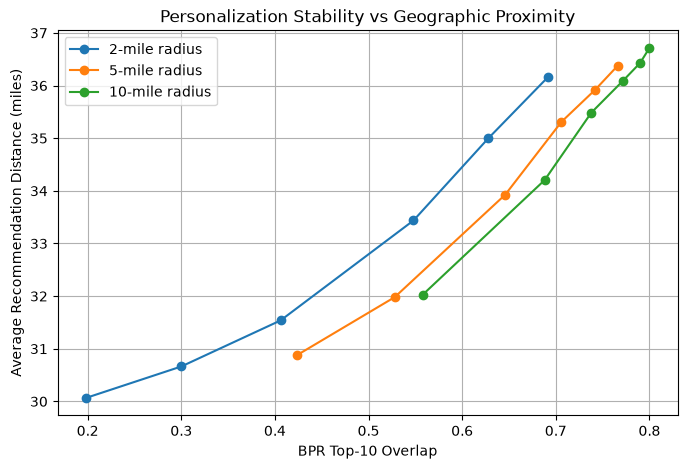

In [39]:
plt.figure(figsize=(8, 5))

for radius in RADII:

    subset = tuning_summary[
        tuning_summary["radius"] == radius
    ]

    plt.plot(
        subset["bpr_overlap"],
        subset["avg_distance"],
        marker="o",
        label=f"{radius}-mile radius"
    )

plt.xlabel("BPR Top-10 Overlap")
plt.ylabel("Average Recommendation Distance (miles)")
plt.title("Personalization Stability vs Geographic Proximity")
plt.legend()
plt.grid(True)
plt.show()


In [1]:
import pandas as pd

def hybrid_distance_rerank(
    candidates,
    user_location,
    radius_miles,
    k=10
):
    """
    Prioritize activities within the preferred radius.
    Use outside-radius candidates to fill remaining slots.
    """

    # Calculate distance for every candidate
    df = add_distance_scores(
        candidates,
        user_location,
        radius_miles
    )

    # Separate nearby and outside-radius activities
    nearby = df[
        df["distance_miles"] <= radius_miles
    ].copy()

    outside = df[
        df["distance_miles"] > radius_miles
    ].copy()

    # Treat missing coordinates as outside-radius candidates
    unknown = df[
        df["distance_miles"].isna()
    ].copy()

    # Rank nearby activities by BPR preference
    nearby = nearby.sort_values(
        "bpr_normalized",
        ascending=False
    )

    # Select up to k nearby activities
    selected = nearby.head(k)

    # Fill remaining slots if necessary
    remaining = k - len(selected)

    if remaining > 0:
        fallback = pd.concat(
            [outside, unknown],
            ignore_index=True
        ).sort_values(
            "bpr_normalized",
            ascending=False
        ).head(remaining)

        selected = pd.concat(
            [selected, fallback],
            ignore_index=True
        )

    return selected.reset_index(drop=True)